# 03. Experimento: cabeza que conserva la posición

Un experimento es un conjunto pequeño de configuraciones que comparten todo salvo la variable que se quiere estudiar. Este notebook corre un experimento y arma la evidencia.

Para otro experimento se duplica el notebook y se cambia la celda de parámetros.

## 0. Hipótesis

**Pregunta:** ¿La CNN aprende a reconocer el tipo de nube o se apoya en su posición respecto al horizonte?

**Observación de partida:** en el EDA, el brillo de arriba menos el de abajo es alto en Sc, St, Ns y Cb, porque se fotografían con el horizonte en la parte baja de la imagen. En Ci, Cc y Ct es negativo, porque se fotografían mirando hacia arriba.

**Hipótesis:** La CNN utiliza la posición de las nubes respecto al horizonte como una pista para clasificarlas. Por ello, esperamos que el volteo vertical reduzca más el recall de las clases de nubes bajas que el de las nubes altas. Asimismo, esperamos que una cabeza de clasificación que conserve información espacial (head_grid = 2) favorezca el reconocimiento de las nubes bajas frente a una cabeza que no conserva esa distribución espacial (head_grid = 1).

**Este notebook prueba:** la segunda parte, con la cabeza de clasificación. Con `head_grid = 1` la red promedia todo el último mapa y no sabe qué estaba arriba o abajo. Con `head_grid = 2` lo promedia en una rejilla de 2x2 y conserva esa información.

**Qué espero ver si es cierta:** con `head_grid = 2` el recall de las nubes bajas sube más que el de las nubes altas, y esa diferencia es mayor que la desviación entre semillas.

**Qué vería si no lo es:** el recall de los dos grupos cambia parecido, o la diferencia queda dentro del ruido entre semillas.

## 1. Parámetros

`CONFIG_FILES` son archivos de `configs/` que pertenecen al mismo experimento. `REFERENCE` es el nombre de la configuración contra la que se comparan las demás.

`EPOCHS` reemplaza las épocas de los TOML en todas las configuraciones. Con 5 épocas la red todavía está aprendiendo, así que sirve para probar el experimento rápido. Para la comparación final se usa el número de épocas fijado en `docs/PROTOCOLO.md`.


In [1]:
CONFIG_FILES = ["cabeza_grid1.toml", "cabeza_grid2.toml"]  # configuraciones a comparar
REFERENCE = "grid1"  # configuración contra la que se comparan las demás
SEEDS = [11, 22, 33]  # tres semillas por configuración para medir la variabilidad
EPOCHS = 5  # épocas de cada corrida, igual para todas para que la comparación sea justa

In [2]:
import numpy as np  # cálculos con arreglos
import pandas as pd  # tablas
from IPython.display import display  # muestra varias tablas en una celda

from nubes import figuras  # gráficas del proyecto
from nubes.config import RunConfig, diff  # configuración y comparación de configuraciones
from nubes.datos import load_manifest  # lectura del manifest
from nubes.experimento import build_model, evaluate_test, run_seeds  # modelo, test y corridas
from nubes.inspeccion import receptive_field  # campo receptivo de la red
from nubes.metricas import symmetric_confusions  # pares de clases confundidas
from nubes.modelo import count_parameters  # tamaño de la red
from nubes.resumen import aggregate, per_class_recall, runs_table, to_markdown, total_confusion
from nubes.utilidades import PROJECT_ROOT  # carpeta raíz del proyecto

configs = {
    # se cambian las épocas y se agrega el número al nombre del experimento para no mezclar
    # estas corridas cortas con las de 30 épocas
    c.name: c.with_changes(epochs=EPOCHS, experiment=f"{c.experiment}_{EPOCHS}ep")
    for c in (RunConfig.from_toml(PROJECT_ROOT / "configs" / f) for f in CONFIG_FILES)
}  # diccionario nombre -> configuración
reference = configs[REFERENCE]  # configuración de referencia
assert len({c.experiment for c in configs.values()}) == 1, (
    "Las configuraciones son de experimentos distintos"
)  # verifica que todas pertenezcan al mismo experimento
_, stats = load_manifest(reference.data_dir)  # estadísticas de la preparación
CLASSES = stats["classes"]  # nombres de las clases
print("experimento:", reference.experiment, "| configuraciones:", list(configs))  # resumen

experimento: cabeza_5ep | configuraciones: ['grid1', 'grid2']


## 2. Qué cambia y qué queda fijo

La primera tabla lista los campos que difieren de la referencia. Todo lo que no aparece es igual. La segunda muestra lo que cada configuración implica para la red.

In [3]:
changes = pd.DataFrame(
    {
        # para cada configuración, los campos que cambian frente a la referencia
        name: {k: after for k, (_, after) in diff(reference, c).items()}
        for name, c in configs.items()
    }
).T.fillna("igual")  # una fila por configuración; donde no cambia dice "igual"
# muestra la tabla, o un aviso si ninguna configuración cambia nada
display(changes if len(changes.columns) else "Ninguna configuración difiere de la referencia")

rows = {}  # una fila por configuración con lo que implica para la red
for name, c in configs.items():  # se recorre cada configuración
    model = build_model(c, len(CLASSES))  # se construye la red sin entrenar
    last = receptive_field(model, c.image_size).iloc[-1]  # campo receptivo del último bloque
    rows[name] = {
        "image_size": c.image_size,  # resolución de entrada
        "último mapa": int(last["map_size"]),  # lado del último mapa de características
        "campo receptivo": int(last["rf"]),  # píxeles de entrada que ve una posición
        "fracción de la imagen": round(float(last["fraction"]), 3),  # fracción de la imagen
        "parámetros": count_parameters(model),  # tamaño de la red
    }
pd.DataFrame(rows).T  # tabla comparativa

,head_grid
grid1,igual
grid2,2.0


,image_size,último mapa,campo receptivo,fracción de la imagen,parámetros
grid1,128.0,8.0,46.0,0.359,422731.0
grid2,128.0,8.0,46.0,0.359,521035.0


## 3. Corridas

In [4]:
# entrena cada configuración con las tres semillas; las corridas que ya existen se cargan
results = {name: run_seeds(c, SEEDS) for name, c in configs.items()}

## 4. Resultados en validation

Media y desviación entre semillas. Una diferencia entre configuraciones menor que la dispersión entre semillas no se puede atribuir a la variable.

In [5]:
table = runs_table(results)  # una fila por corrida
summary = aggregate(table)  # media y desviación entre semillas por configuración
display(table.round(4))  # muestra las corridas una por una
display(summary.round(4))  # muestra el resumen
print(to_markdown(summary))  # imprime la tabla lista para pegar en la bitácora

,config,seed,best_epoch,val_loss,val_acc,val_macro_f1,train_acc,gap,val_errors,seconds_per_epoch,parameters
0,grid1,11,4,2.1118,0.2147,0.1558,0.2681,0.0535,300,35.2313,422731
1,grid1,22,5,2.0828,0.2644,0.1777,0.2771,0.0127,281,33.8806,422731
2,grid1,33,5,2.1079,0.2618,0.1871,0.2777,0.0159,282,34.4910,422731
3,grid2,11,5,2.0533,0.2775,0.2092,0.3182,0.0407,276,33.8447,521035
4,grid2,22,5,2.0724,0.2592,0.2017,0.3058,0.0466,283,32.8713,521035
5,grid2,33,5,2.0973,0.2696,0.2221,0.3041,0.0345,279,33.1314,521035


seeds val_macro_f1         val_acc         val_loss         train_acc  \
                     mean     std    mean     std     mean     std      mean   
config                                                                         
grid1      3       0.1735  0.0161  0.2469  0.0280   2.1008  0.0158    0.2743   
grid2      3       0.2110  0.0103  0.2688  0.0092   2.0744  0.0221    0.3093   

                   gap         best_epoch         seconds_per_epoch          
           std    mean     std       mean     std              mean     std  
config                                                                       
grid1   0.0054  0.0274  0.0227     4.6667  0.5774           34.5343  0.6764  
grid2   0.0077  0.0406  0.0061     5.0000  0.0000           33.2825  0.5040

| config | seeds | val_macro_f1 | val_acc | val_loss | train_acc | gap | best_epoch | seconds_per_epoch |
|---|---|---|---|---|---|---|---|---|
| grid1 | 3 | 0.174 ± 0.016 | 0.247 ± 0.028 | 2.101 ± 0.016 | 0.274 ± 0.005 | 0.027 ± 0.023 | 4.7 ± 0.6 | 34.5 ± 0.7 |
| grid2 | 3 | 0.211 ± 0.010 | 0.269 ± 0.009 | 2.074 ± 0.022 | 0.309 ± 0.008 | 0.041 ± 0.006 | 5.0 ± 0.0 | 33.3 ± 0.5 |


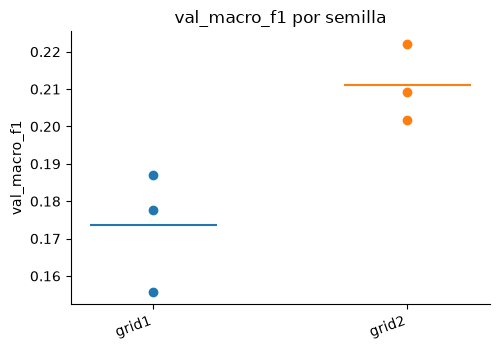

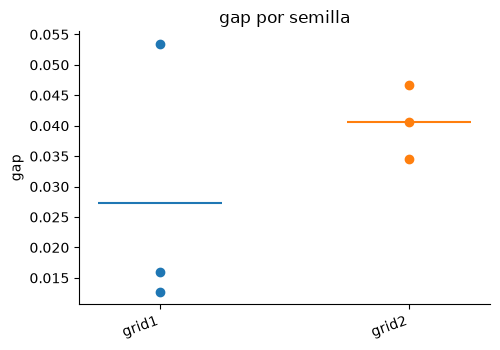

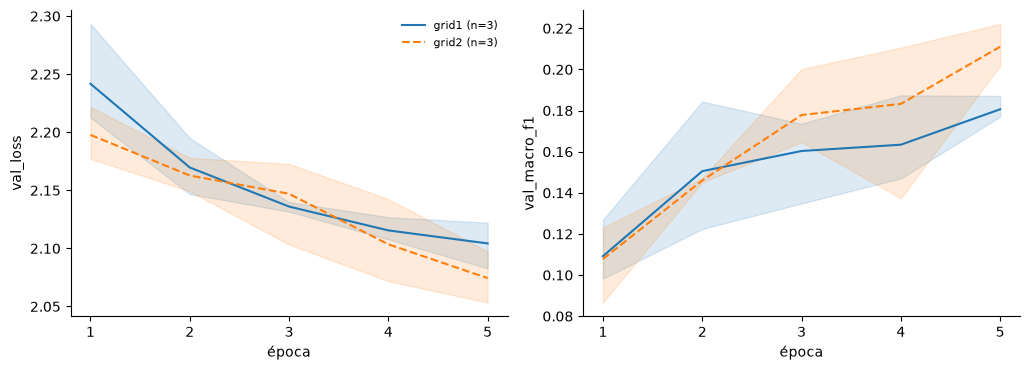

In [6]:
figuras.plot_seed_points(table, "val_macro_f1")  # macro f1 de cada semilla por configuración
figuras.plot_seed_points(table, "gap")  # generalization gap de cada semilla
figuras.plot_comparison(results);  # curvas de validation, media y rango entre semillas

**Observación:**

Con `head_grid = 2` el macro F1 subió de 0.174 a 0.211 y la accuracy de 0.247 a 0.269. La diferencia en macro F1 es mayor que la desviación entre semillas, así que sí se distingue del ruido. La diferencia en accuracy es menor que la desviación de `grid1`, que fue de 0.028. El gap subió de 0.027 a 0.041, porque `grid2` aprende un poco más rápido train con la misma cantidad de épocas.

## 5. Por clase

La hipótesis casi nunca predice lo mismo para todas las clases. La primera tabla es el recall medio. La segunda es el cambio frente a la referencia y la tercera la desviación entre semillas, que da la escala para leer ese cambio.

,grid1,grid2
Ac,0.000,0.020
As,0.500,0.345
Cb,0.631,0.766
Cc,0.349,0.302
Ci,0.000,0.015
Cs,0.111,0.087
Ct,0.289,0.578
Cu,0.074,0.123
Ns,0.056,0.135
Sc,0.471,0.392


,grid2
Ac,0.020
As,-0.155
Cb,0.135
Cc,-0.047
Ci,0.015
Cs,-0.024
Ct,0.289
Cu,0.049
Ns,0.079
Sc,-0.078


,grid1,grid2
Ac,0.000,0.017
As,0.000,0.144
Cb,0.016,0.068
Cc,0.262,0.040
Ci,0.000,0.026
Cs,0.153,0.084
Ct,0.069,0.077
Cu,0.064,0.086
Ns,0.077,0.113
Sc,0.137,0.039


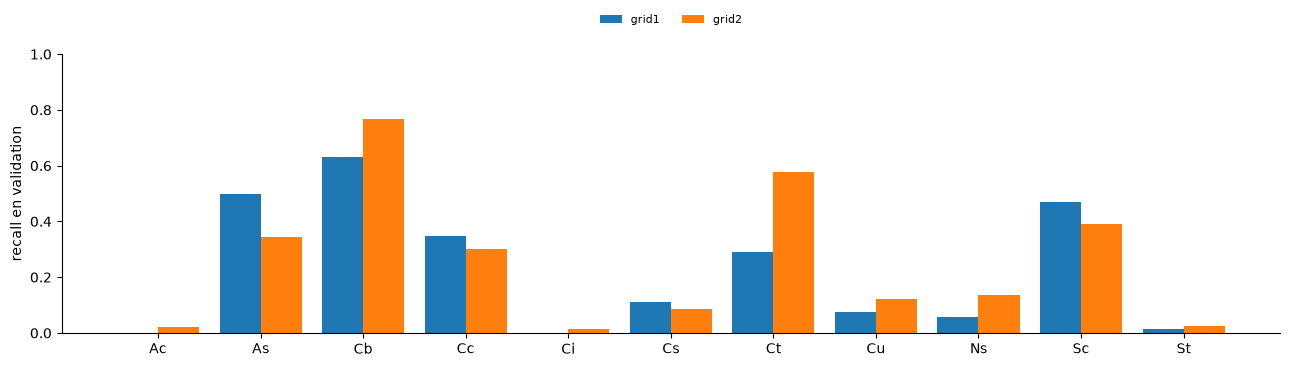

In [7]:
recall = per_class_recall(results, CLASSES)  # recall medio por clase y configuración
recall_std = per_class_recall(results, CLASSES, stat="std")  # desviación entre semillas
figuras.plot_recall_by_class(recall)  # barras agrupadas de recall por clase
display(recall.round(3))  # tabla de recall medio
# cambio de recall de cada configuración frente a la referencia
display(recall.sub(recall[REFERENCE], axis=0).drop(columns=REFERENCE).round(3))
recall_std.round(3)  # escala para saber si un cambio es mayor que el ruido entre semillas

### Recall por grupo de altura

La hipótesis no habla de clases sueltas sino de nubes bajas frente a nubes altas. Esta tabla promedia el cambio de recall dentro de cada grupo.

In [8]:
GROUPS = {
    "bajas": ["Sc", "St", "Ns", "Cb"],  # clases que en el eda aparecen con el horizonte abajo
    "altas": ["Ci", "Cc", "Cs", "Ct"],  # clases que se fotografían mirando hacia arriba
}  # las demás clases (Ac, As, Cu) no entran en esta comparación
change = recall.sub(recall[REFERENCE], axis=0).drop(columns=REFERENCE)  # cambio frente a la referencia
pd.DataFrame(
    {group: change.loc[codes].mean() for group, codes in GROUPS.items()}  # promedio por grupo
).T.round(3)  # una fila por grupo y una columna por configuración

,grid2
bajas,0.037
altas,0.058


,par,a→b,b→a,total
0,Ns / Sc,45,18,63
1,Cb / Sc,9,48,57
2,Cb / Ns,7,40,47
3,Cc / Ct,38,7,45
4,Cs / Sc,28,12,40
5,Cc / Cs,16,20,36


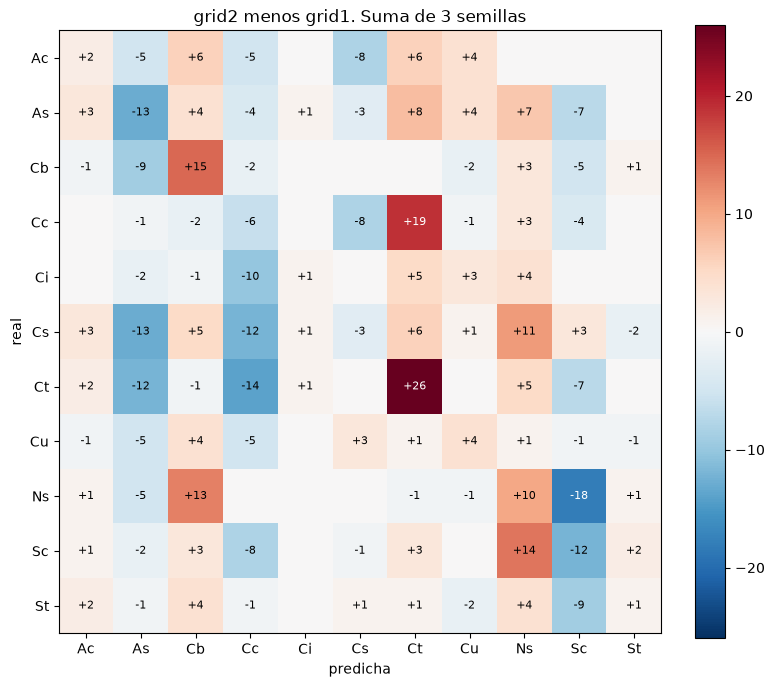

In [9]:
reference_confusion = total_confusion(results[REFERENCE])  # matriz de la referencia, 3 semillas
for name, runs in results.items():  # se recorre cada configuración
    if name == REFERENCE:  # la referencia no se compara consigo misma
        continue
    change = total_confusion(runs) - reference_confusion  # diferencia casilla por casilla
    figuras.plot_matrix(
        change,  # matriz de diferencias
        CLASSES,  # nombres de las clases
        fmt="+d",  # enteros con signo
        cmap="RdBu_r",  # rojo sube, azul baja
        diverging=True,  # escala simétrica alrededor de cero
        title=f"{name} menos {REFERENCE}. Suma de {len(SEEDS)} semillas",  # título
    )
    display(symmetric_confusions(total_confusion(runs), CLASSES, k=6))  # sus 6 pares más confusos

**Observación:**

El promedio del recall subió +0.037 en las nubes bajas y +0.058 en las altas, así que la mejora fue mayor en las altas. Dentro de las bajas subieron Cb (+0.135) y Ns (+0.079) pero bajó Sc (−0.078). La clase que más mejoró fue Ct (+0.289), que es alta y tiene una forma alargada que atraviesa el cielo. As bajó −0.155. Las confusiones más fuertes de `grid2` siguen siendo Ns predicha como Sc, Cb con Sc y Cb con Ns.

## 6. Costo

In [10]:
# tiempo por época, mejor época y tamaño de la red, promediados por configuración
table.groupby("config", sort=False)[["seconds_per_epoch", "best_epoch", "parameters"]].mean().round(
    1
)

,seconds_per_epoch,best_epoch,parameters
config,,,
grid1,34.5,4.7,422731.0
grid2,33.3,5.0,521035.0


## 7. Veredicto

**Qué se observó:** con `head_grid = 2` el macro F1 subió de 0.174 a 0.211, una diferencia mayor que la desviación entre semillas. El recall subió +0.037 en las nubes bajas y +0.058 en las altas, y la clase que más mejoró fue Ct.

**Qué se interpreta:** conservar la posición sí ayuda a la red, pero no ayuda más a las nubes bajas, que era lo que esperábamos.

**La hipótesis se sostiene, no se sostiene o no se puede decidir:** no se sostiene.

**Qué limita esta conclusión:** `grid2` tiene 521 035 parámetros y `grid1` 422 731, así que parte de la mejora puede venir de tener una cabeza más grande y no solo de conservar la posición. Además son 5 épocas, y la red todavía no reconoce bien varias clases.

## 8. Evaluación final en test

Solo al final del proyecto y solo para la configuración elegida con validation. Cada corrida se puede evaluar una vez. El resultado queda en `test.json` dentro de su carpeta.

,seed,val_acc,test_acc,val_macro_f1,test_macro_f1
0,11,0.2775,0.3089,0.2092,0.2200
1,22,0.2592,0.2984,0.2017,0.2346
2,33,0.2696,0.2932,0.2221,0.2273


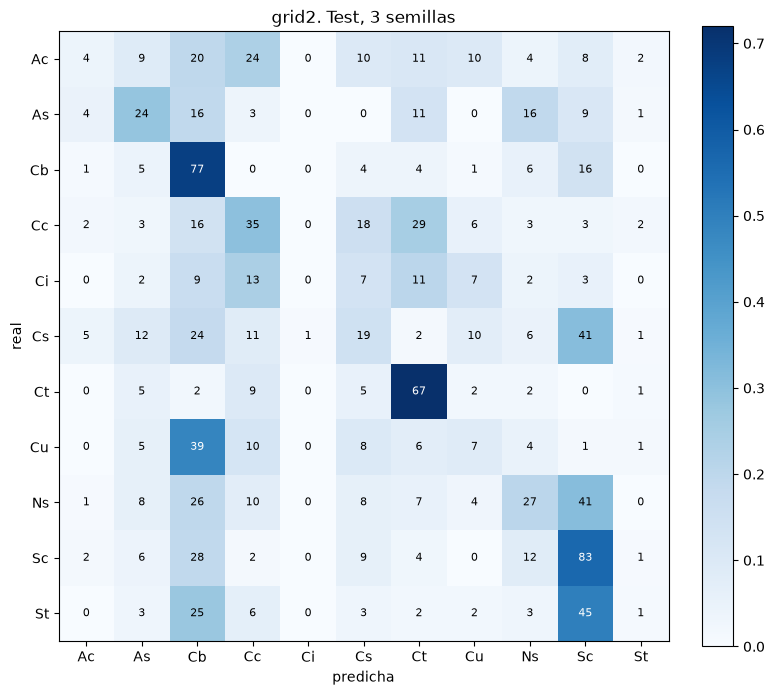

In [11]:
EVALUATE_TEST = True  # se cambia a True solo al final del proyecto
FINAL = "grid2"  # configuración elegida con validation: el mayor macro f1

if EVALUATE_TEST:  # esta parte solo corre cuando se habilita
    reports = [evaluate_test(r.run_dir) for r in results[FINAL]]  # test una vez por semilla
    final = pd.DataFrame(
        {
            "seed": [r.config.seed for r in results[FINAL]],  # semilla
            "val_acc": [r.val.accuracy for r in results[FINAL]],  # accuracy de validation
            "test_acc": [t.accuracy for t in reports],  # accuracy de test
            "val_macro_f1": [r.val.macro_f1 for r in results[FINAL]],  # macro f1 de validation
            "test_macro_f1": [t.macro_f1 for t in reports],  # macro f1 de test
        }
    )  # tabla validation frente a test
    display(final.round(4))  # muestra la tabla
    figuras.plot_matrix(
        sum(np.asarray(t.confusion) for t in reports),  # matriz de test sumada entre semillas
        CLASSES,  # nombres de las clases
        normalize=True,  # color por fracción de cada fila
        title=f"{FINAL}. Test, {len(reports)} semillas",  # título
    )

**Observación:**

En test la accuracy media fue 0.300 y el macro F1 0.227, un poco por encima de validation, que fue 0.269 y 0.211. La diferencia en accuracy equivale a unas 12 imágenes de 382 y es del tamaño de la variación entre semillas. Esto muestra que el resultado de validation no era optimista. Igual que en validation, la red no reconoce Ci ni St y reconoce mejor Ct y Cb. Como es un modelo de 5 épocas, este número describe una red que todavía está aprendiendo y no el mejor resultado posible de la arquitectura.